Tổng số ảnh dự đoán sai: 5940 / 6149


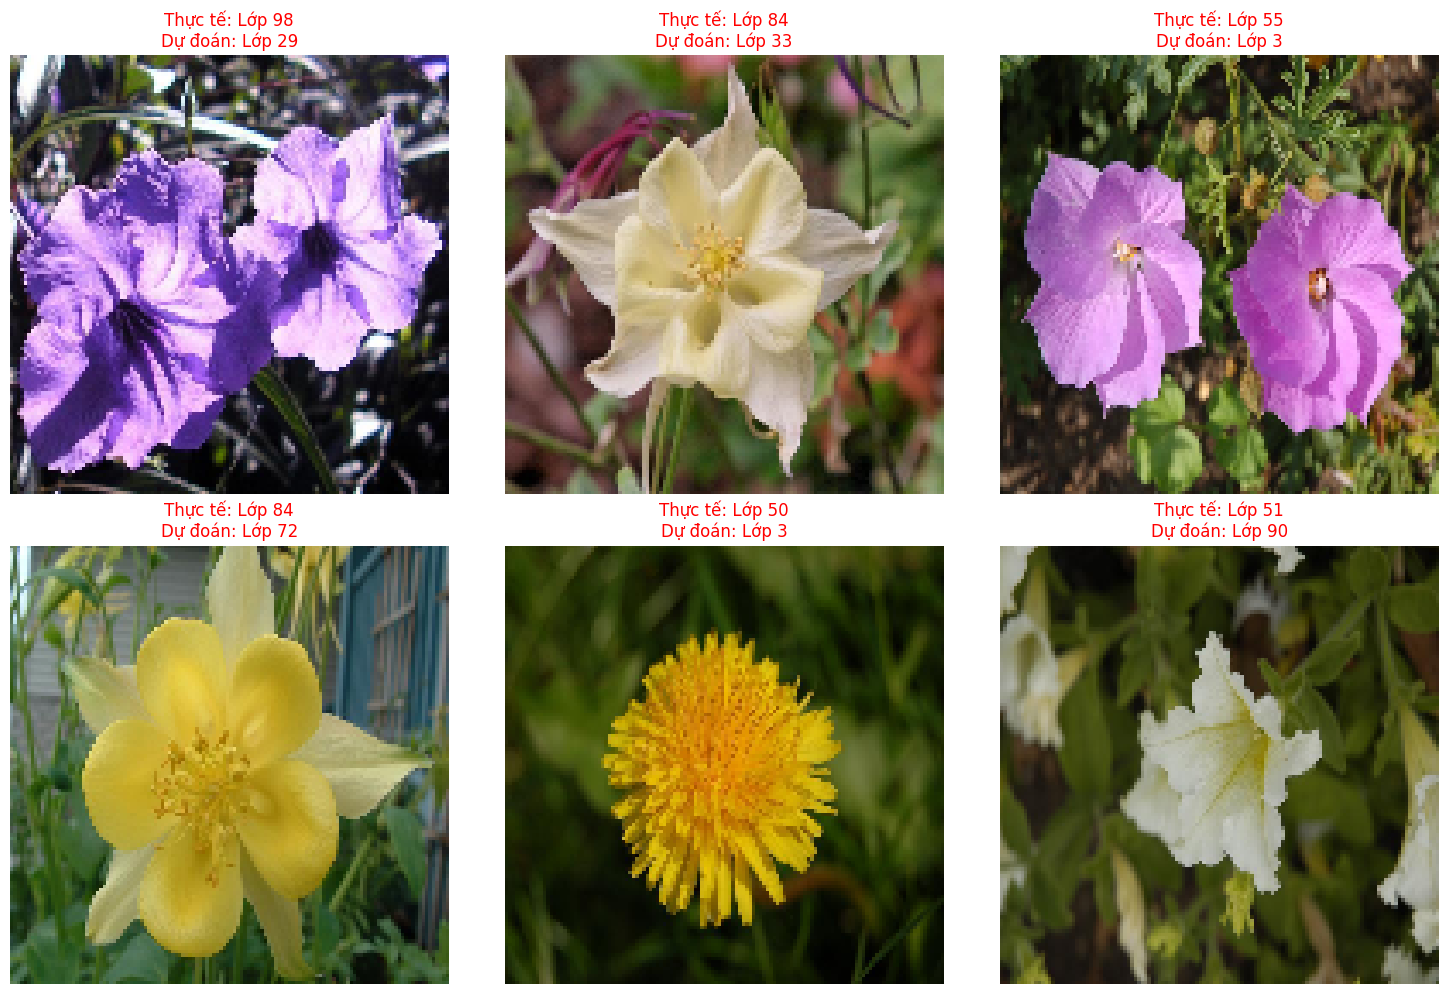

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
import joblib

# 1. Load lại mô hình và dữ liệu
PROCESSED_DIR = Path("../data/processed")
DATA_DIR = Path("../data/raw")
MODEL_DIR = Path("../models")

X_test = np.load(PROCESSED_DIR / "X_test.npy") # Lấy lại ảnh gốc (chưa qua PCA) để hiển thị
y_test = np.load(PROCESSED_DIR / "y_test.npy")
X_test_pca = np.load(PROCESSED_DIR / "X_test_pca.npy") if (PROCESSED_DIR / "X_test_pca.npy").exists() else None

# Load mô hình
scaler = joblib.load(MODEL_DIR / "scaler_knn.pkl")
pca = joblib.load(MODEL_DIR / "pca_knn.pkl")
knn = joblib.load(MODEL_DIR / "knn_model.pkl")

# (Nếu chưa lưu X_test_pca thì phải transform lại)
if X_test_pca is None:
    X_test_pca = pca.transform(scaler.transform(X_test))

# Dự đoán
y_pred = knn.predict(X_test_pca)

# 2. Tìm các ảnh dự đoán SAI
wrong_indices = np.where(y_pred != y_test)[0]
print(f"Tổng số ảnh dự đoán sai: {len(wrong_indices)} / {len(y_test)}")

# 3. Hiển thị 6 ảnh dự đoán sai ngẫu nhiên để phân tích
np.random.seed(42)
sample_wrong = np.random.choice(wrong_indices, 6, replace=False)

def load_img_by_idx(idx):
    # Cần map lại index của tập Test về ID gốc của ảnh
    import scipy.io
    setid = scipy.io.loadmat(DATA_DIR / "setid.mat")
    test_ids = setid["tstid"][0] - 1
    real_img_id = test_ids[idx] # ID gốc
    
    path = DATA_DIR / "jpg" / f"image_{real_img_id+1:05d}.jpg"
    img = cv2.imread(str(path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (128, 128))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, idx in zip(axes.flatten(), sample_wrong):
    img = load_img_by_idx(idx)
    ax.imshow(img)
    ax.set_title(f"Thực tế: Lớp {y_test[idx]}\nDự đoán: Lớp {y_pred[idx]}", color='red')
    ax.axis('off')

plt.tight_layout()
plt.show()